# Notebook exécuté — sorties réelles incluses

**El Mehdi FATAHLLAH — Master 2 Data & IA**

Les **30 cellules de code** de cette copie ont été exécutées sans erreur dans un environnement **CPU**. Les tableaux, graphiques, images, transcriptions, légendes et vidéos ci-dessous proviennent de cette exécution réelle. Vous pouvez les consulter sans démarrer une machine Colab.

| Partie | Exécution effectuée |
|---|---|
| Tracking | YOLO + ByteTrack sur **62 frames** de vidéo réelle ; trajectoires et vidéo annotée |
| Métriques tracking | IoU, MOTA, IDF1 et HOTA sur la séquence contrôlée, avec vérité terrain connue |
| Génération | **4 images** de chats avec SD-Turbo, 512 × 512, 1 étape, 4 seeds ; CLIPScore et latences |
| OCR | EasyOCR sur texte net et flou ; CER/WER |
| Captioning | BLIP sur 3 images ; BLEU-1, BLEU-4 lissé, METEOR et CIDEr |
| Retrieval | CLIP sur 3 requêtes et 3 images ; R@K et MRR |

**Conditions de calcul :** PyTorch CPU ; SD-Turbo en **bfloat16** pour limiter la mémoire. Les latences sont celles du CPU, pas celles d'un GPU T4. Le premier chargement des poids n'est pas une mesure d'inférence.

**Extensions non activées :** LPIPS et FID/KID. Les cellules associées affichent explicitement leur désactivation. FID/KID nécessitent des lots de données adaptés, et ne sont pas calculés artificiellement sur quatre images.

Les illustrations embarquées du mini-catalogue sont générées par IA et servent de données pédagogiques pour BLIP/CLIP. Les quatre chats produits dans la section génération sont, eux, les sorties réelles du modèle SD-Turbo exécuté ici.

Le notebook d'origine est conservé ; cette copie ajoute les sorties et les adaptations CPU.


# Évaluer la vision par ordinateur : trois sujets dans un seul notebook
**El Mehdi FATAHLLAH — Master 2 Data & IA**

1. **Object tracking** : vidéo de piétons avec YOLO + ByteTrack ; IoU, MOTA, IDF1 et HOTA sur un exemple contrôlé.
2. **Image Generation** : SD-Turbo génère un chat ; alignement CLIPScore, temps de calcul et audit visuel ; LPIPS et FID/KID en extensions.
3. **OCR, Captioning, Retrieval** : lecture de « TOTAL 25 », description d'images avec BLIP et recherche texte → images avec CLIP.

Chaque cellule de code est précédée d'une description : **objectif, fonctionnement et résultat attendu**. Les commentaires expliquent les étapes importantes.

## Avant de commencer dans Colab
- Choisir **Exécution → Modifier le type d'exécution → GPU T4**, puis exécuter de haut en bas.
- Les poids des modèles et la vidéo de démonstration nécessitent Internet. Leur téléchargement peut prendre plusieurs minutes. Aucun abonnement à une API n'est nécessaire ; les modèles s'exécutent dans votre session Colab.
- Un GPU est nécessaire pour une génération confortable. La copie exécutée utilise le CPU pour toutes les tâches.
- Les trois images du mini-catalogue sont **embarquées dans ce fichier** : elles reprennent les illustrations de la présentation (piétons, chat, chien). Ce sont des **images générées par IA**, destinées à la démonstration, pas un benchmark de photos réelles.
- Les sorties de la session sont éphémères : la dernière partie prépare un ZIP à télécharger.

**Rigueur expérimentale :** aucun score de modèle n'est prérempli. Les métriques apparaissent après exécution. La vidéo réelle n'a pas de vérité terrain embarquée : ses scores de tracking ne sont donc pas inventés. Les scores MOTA/IDF1/HOTA sont calculés séparément sur une séquence contrôlée annotée par construction.

## Plan d'exécution
| Étape | Entrée | Sortie |
|---|---|---|
| Préparation | Bibliothèques + images embarquées | Dossiers, configuration et mini-catalogue |
| Tracking réel | Vidéo de piétons | Vidéo annotée + trajectoires CSV/MOT |
| Évaluation du tracking | Boîtes et IDs connus | IoU, MOTA, IDF1, HOTA |
| Génération | Prompt + seeds | 4 images de chats + mesures |
| OCR | Texte synthétique net/flou | Texte reconnu, CER/WER |
| Captioning | Mini-catalogue + références | BLIP, BLEU, METEOR, CIDEr |
| Retrieval | Requêtes + pertinences | Classement, R@K, MRR |
| Export | Résultats mesurés | CSV, JSON, images, vidéos, ZIP |


### Cellule 01 — Vérifier les versions utilisées

**Objectif.** Identifier les bibliothèques réellement utilisées pour cette exécution.

**Ce que fait le code.** Les dépendances ont été installées avant le lancement ; importlib.metadata affiche leurs versions exactes.

**Résultat attendu.** Une liste des versions de PyTorch, Ultralytics, Diffusers, Transformers et des outils d'évaluation.


In [1]:
# Dépendances déjà installées avant cette exécution ; affichage des versions réelles.
import importlib.metadata as metadata
for name in ['torch','torchvision','ultralytics','diffusers','transformers','easyocr','motmetrics','nbclient']:
    print(name, metadata.version(name))


torch 2.7.1+cpu
torchvision 0.22.1+cpu
ultralytics 8.4.208
diffusers 0.36.0
transformers 4.57.6
easyocr 1.7.2
motmetrics 1.4.0
nbclient 0.11.0


### Cellule 02 — Configurer la session

**Objectif.** Centraliser les options, les seeds et les dossiers.

**Ce que fait le code.** Le code choisit CUDA si disponible, fixe les seeds et crée un dictionnaire report. Les modèles lourds sont utilisés successivement pour limiter la mémoire.

**Résultat attendu.** Le matériel utilisé et le dossier cv_results sont affichés.


In [2]:
from pathlib import Path
import os, sys, io, json, time, gc, base64, random, re, shutil, itertools, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from IPython.display import display, Video
import torch

torch.set_num_threads(6)
torch.set_num_interop_threads(2)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ROOT = Path('cv_results'); ROOT.mkdir(exist_ok=True)
for folder in ['assets','tracking','generation','ocr','captioning','retrieval']:
    (ROOT/folder).mkdir(exist_ok=True)
RUN_REAL_TRACKING = True
RUN_GENERATION = True
RUN_LPIPS = False                 # Extension : téléchargement d'un réseau perceptuel.
RUN_DISTRIBUTION = False          # Extension : vrais lots réels/générés à importer.
VIDEO_SOURCE = 'demo'             # 'upload' pour importer votre propre vidéo.
MAX_FRAMES = 180                  # Limite de coût et de taille pour la vidéo réelle.
report = {'seed': SEED, 'device': DEVICE, 'tracking': {}, 'generation': {},
          'ocr': {}, 'captioning': {}, 'retrieval': {}}
print('Device :', DEVICE, '| Résultats :', ROOT.resolve())
if DEVICE == 'cuda': print('GPU :', torch.cuda.get_device_name(0))
else: print('Exécution CPU : modèles plus lents ; SD-Turbo utilisera bfloat16.')

def release_cuda():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def show_gallery(images, titles=None, columns=3, size=(12,5)):
    if not images:
        print('Aucune image à afficher.'); return
    rows = (len(images)+columns-1)//columns
    fig, axes = plt.subplots(rows,columns,figsize=(size[0],size[1]*rows),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for i,(ax,image) in enumerate(zip(axes.flat,images)):
        ax.imshow(image)
        if titles is not None: ax.set_title(titles[i],fontsize=11)
    plt.tight_layout(); plt.show()


Device : cpu | Résultats : /workspace/scratch/aaef0a09509f/executed_cv_work/cv_results
Exécution CPU : modèles plus lents ; SD-Turbo utilisera bfloat16.


## Données embarquées : un mini-catalogue autonome
La cellule suivante contient trois JPEG encodés en Base64. Cette représentation est technique : **inutile de modifier les longues chaînes**. La cellule est repliée par défaut dans les interfaces qui le permettent. Elle reconstruit les images pour les parties captioning et retrieval ; elle ne génère pas de nouvelles images et ne remplace pas SD-Turbo.


### Cellule 03 — Restaurer les images embarquées

**Objectif.** Disposer des mêmes exemples sans dépendre de liens externes.

**Ce que fait le code.** base64.b64decode reconstruit les octets JPEG ; PIL les ouvre puis les sauvegarde dans assets.

**Résultat attendu.** Trois images disponibles : pedestrians, cat, dog.


In [3]:
EMBEDDED_JPEG = {"pedestrians": "...", "cat": "...", "dog": "..."}

catalogue = {}
for name, encoded in EMBEDDED_JPEG.items():
    image = Image.open(io.BytesIO(base64.b64decode(encoded))).convert("RGB")
    catalogue[name] = image
    image.save(ROOT/"assets"/(name+".jpg"))
print("Images restaurées :", list(catalogue))


Images restaurées : ['pedestrians', 'cat', 'dog']


### Cellule 04 — Afficher les entrées et fixer les références

**Objectif.** Séparer les annotations des prédictions.

**Ce que fait le code.** On observe les images et définit plusieurs légendes anglaises et les pertinences des requêtes avant de charger BLIP/CLIP. Les requêtes sont génériques pour illustrer les catégories.

**Résultat attendu.** Les images et les références sont affichées. Vous pouvez enrichir les références avant de poursuivre.


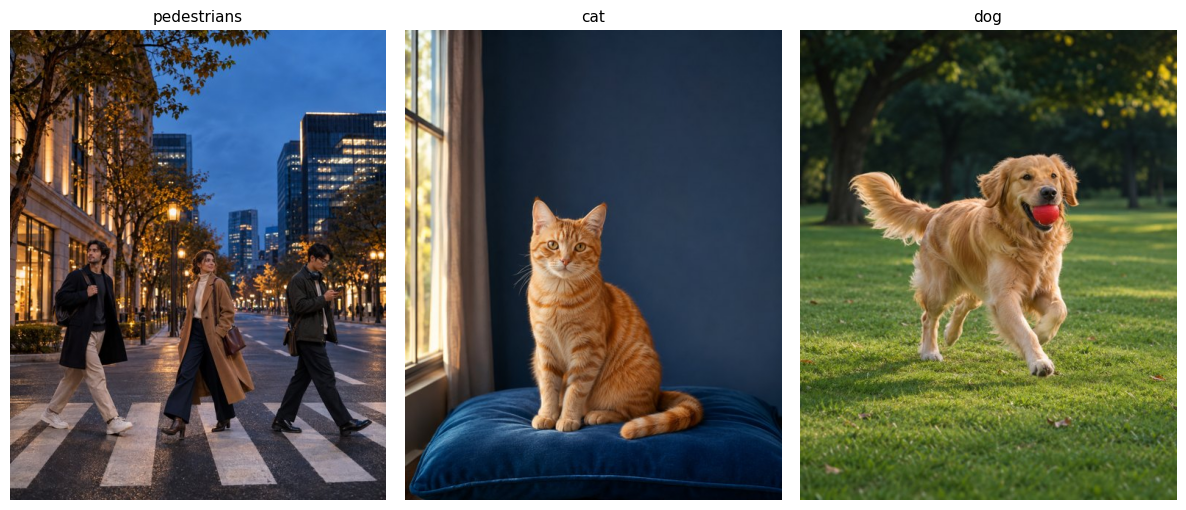

,image,références
0,pedestrians,"[three people are crossing a city street, pede..."
1,cat,"[an orange cat sits on a blue cushion, a ginge..."
2,dog,"[a dog runs in a green park with a red ball, a..."


In [4]:
show_gallery(list(catalogue.values()),list(catalogue))
REFERENCES = {
 'pedestrians': ['three people are crossing a city street', 'pedestrians walk across a crosswalk'],
 'cat': ['an orange cat sits on a blue cushion', 'a ginger cat is sitting near a window'],
 'dog': ['a dog runs in a green park with a red ball', 'a golden retriever carries a red ball in its mouth']
}
QUERIES = ['a cat', 'a dog', 'pedestrians']
RELEVANT = [{'cat'}, {'dog'}, {'pedestrians'}]
assert len(QUERIES)==len(RELEVANT)
for names in RELEVANT: assert names and names <= set(catalogue)
annotation = {'references': REFERENCES, 'queries': QUERIES,
              'relevant': [sorted(s) for s in RELEVANT], 'source': 'illustrations générées par IA'}
(ROOT/'assets'/'annotations.json').write_text(json.dumps(annotation,ensure_ascii=False,indent=2))
display(pd.DataFrame({'image': list(REFERENCES), 'références': list(REFERENCES.values())}))


# 1. Object tracking : suivre des piétons
Un détecteur produit des boîtes. Un tracker maintient une identité dans le temps. La première démonstration fait réellement tourner **YOLO + ByteTrack** sur une vidéo ; la seconde isole le calcul des métriques sur un cas contrôlé.

**Lien avec la présentation :** IoU → appariement spatial ; MOTA → erreurs de détection et changements d'ID ; IDF1 → cohérence globale des identités ; HOTA → équilibre détection/association.


### Cellule 05 — Charger une vidéo réelle de piétons

**Objectif.** Fournir une entrée au détecteur et au tracker.

**Ce que fait le code.** Le mode demo utilise la courte vidéo publiée dans le tutoriel officiel Ultralytics. Le mode upload ouvre le sélecteur de fichiers Colab. OpenCV vérifie que la vidéo est lisible.

**Résultat attendu.** Dimensions, FPS et nombre d’images. En cas de lien indisponible, passer VIDEO_SOURCE à upload et relancer cette cellule.


Vidéo : 640 × 360 | FPS : 30.0 | images : 62


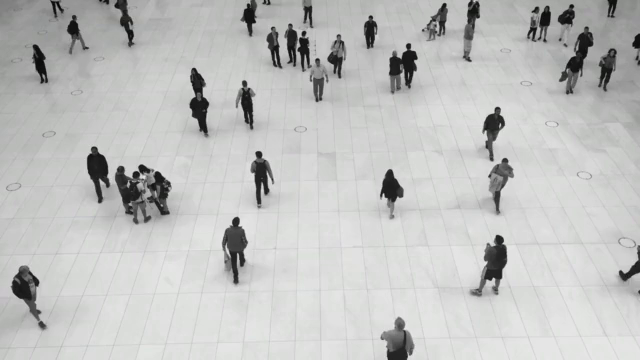

In [5]:
import cv2, requests
video_path = None
if RUN_REAL_TRACKING:
    if VIDEO_SOURCE == 'upload':
        from google.colab import files
        uploaded = files.upload()
        if not uploaded: raise ValueError('Aucune vidéo importée.')
        video_path = Path(next(iter(uploaded)))
    elif VIDEO_SOURCE == 'demo':
        video_path = ROOT/'tracking'/'input_people.mp4'
        url = 'https://github.com/ultralytics/assets/releases/download/v0.0.0/solutions_ci_demo.mp4'
        if not video_path.exists():
            try:
                with requests.get(url,stream=True,timeout=(15,120)) as response:
                    response.raise_for_status()
                    with open(video_path,'wb') as stream:
                        for chunk in response.iter_content(1024*1024):
                            if chunk: stream.write(chunk)
            except requests.RequestException as exc:
                if video_path.exists(): video_path.unlink()
                raise RuntimeError("Vidéo inaccessible : mettre VIDEO_SOURCE='upload' puis relancer.") from exc
    else: raise ValueError("VIDEO_SOURCE doit être 'demo' ou 'upload'.")
    cap = cv2.VideoCapture(str(video_path))
    ok,first = cap.read()
    if not ok:
        cap.release(); raise RuntimeError('Vidéo illisible : importer un autre MP4.')
    fps_in = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps_in) or fps_in <= 0: fps_in=25.0
    print('Vidéo :', first.shape[1], '×', first.shape[0], '| FPS :', round(fps_in,2),
          '| images :', int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    cap.release(); display(Image.fromarray(cv2.cvtColor(first,cv2.COLOR_BGR2RGB)))
else: print('Tracking réel désactivé ; l’évaluation contrôlée reste active.')


### Cellule 06 — Détecter et suivre avec YOLO + ByteTrack

**Objectif.** Implémenter réellement le suivi multi-objets.

**Ce que fait le code.** YOLO détecte uniquement la classe person. ByteTrack associe les détections ; persist=True conserve l’état entre les images. Les IDs et boîtes sont exportés avec le numéro de frame. On ne compte pas les IDs uniques comme un nombre exact de personnes.

**Résultat attendu.** Une vidéo annotée tracking_people.mp4 et un CSV de trajectoires. Aucun score MOTA/IDF1 n’est calculé sur cette vidéo sans annotations.


In [6]:
import imageio.v2 as imageio
tracking_rows = []; annotated_path = ROOT/'tracking'/'tracking_people.mp4'
if RUN_REAL_TRACKING:
    from ultralytics import YOLO
    detector = YOLO('yolo11n.pt')
    person_ids = [i for i,n in detector.names.items() if n=='person']
    assert person_ids, 'Classe person absente du modèle.'
    cap = cv2.VideoCapture(str(video_path))
    writer = imageio.get_writer(str(annotated_path),fps=float(fps_in),codec='libx264',quality=7,macro_block_size=2)
    started = time.perf_counter(); processed=0
    try:
        for frame_id in range(1,MAX_FRAMES+1):
            ok,frame = cap.read()
            if not ok: break
            result = detector.track(frame,persist=True,tracker='bytetrack.yaml',classes=person_ids,
                                    conf=0.1,imgsz=640,verbose=False,device=0 if DEVICE=='cuda' else 'cpu')[0]
            writer.append_data(cv2.cvtColor(result.plot(),cv2.COLOR_BGR2RGB))
            if result.boxes.id is not None:
                boxes=result.boxes.xyxy.cpu().numpy(); ids=result.boxes.id.int().cpu().tolist()
                confs=result.boxes.conf.cpu().tolist()
                for track_id,(x1,y1,x2,y2),confidence in zip(ids,boxes,confs):
                    tracking_rows.append([frame_id,track_id,float(x1),float(y1),float(x2-x1),float(y2-y1),float(confidence)])
            processed+=1
    finally:
        cap.release(); writer.close()
    elapsed=time.perf_counter()-started
    trajectories=pd.DataFrame(tracking_rows,columns=['frame','id','x','y','w','h','confidence'])
    trajectories.to_csv(ROOT/'tracking'/'trajectories.csv',index=False)
    # Format MOTChallenge pour une éventuelle évaluation après annotation manuelle.
    mot=trajectories.copy()
    mot[['x','y']] += 1  # Conversion des coordonnées OpenCV 0-based vers MOT 1-based.
    mot[['x','y']] += 1  # Conversion des coordonnées OpenCV 0-based vers MOT 1-based.
    mot[['x','y']] += 1  # Conversion des coordonnées OpenCV 0-based vers MOT 1-based.
    for col in ['unused1','unused2','unused3']: mot[col]=-1
    mot.to_csv(ROOT/'tracking'/'predictions_mot.txt',header=False,index=False)
    report['tracking']['real_video']={'frames':processed,'seconds':elapsed,
        'fps_pipeline': processed/max(elapsed,1e-9), 'track_ids': int(trajectories['id'].nunique()),
        'ground_truth_available':False, 'quality_scores_computed':False}
    print('Frames traitées :',processed,'| IDs produits :',trajectories['id'].nunique())
    print('FPS pipeline (inclut encodage et démarrage) :',round(processed/max(elapsed,1e-9),2))
    display(Video(str(annotated_path),embed=True))
    del detector, result; release_cuda()
else: print('Cellule ignorée selon RUN_REAL_TRACKING.')


Frames traitées : 62 | IDs produits : 24
FPS pipeline (inclut encodage et démarrage) : 14.15


## Évaluation contrôlée : pourquoi une vidéo convaincante ne suffit pas
Pour calculer une métrique, il faut connaître les boîtes et identités correctes. Nous construisons donc deux trajectoires de piétons sous forme de boîtes :
- **condition parfaite** : toutes les boîtes et identités sont correctes ;
- **condition dégradée** : cinq détections manquées, une fausse détection et une rupture des deux identités à mi-séquence.

Il s'agit de **prédictions simulées pour tester les métriques**, pas des sorties de YOLO sur la vidéo précédente.


### Cellule 07 — Construire la vérité terrain et les prédictions contrôlées

**Objectif.** Obtenir un jeu où chaque erreur est connue.

**Ce que fait le code.** Les dictionnaires contiennent, pour chaque frame, une liste (ID, boîte xywh). Un changement d’ID ne change pas nécessairement la position de la boîte.

**Résultat attendu.** 60 frames, 120 occurrences de piétons annotées, deux conditions de prédiction.


In [7]:
GT={}; PERFECT={}; DEGRADED={}
for t in range(60):
    boxes=[np.array([20+4*t,45,28,72],dtype=float),np.array([330-4*t,145,28,72],dtype=float)]
    GT[t]=[(i+1,b.copy()) for i,b in enumerate(boxes)]
    PERFECT[t]=[(i,b.copy()) for i,b in GT[t]]
    items=[]
    for object_id,b in GT[t]:
        if object_id==1 and 20<=t<25: continue
        predicted_id=object_id+(100 if t>=30 else 0)
        items.append((predicted_id,b.copy()))
    if t==10: items.append((999,np.array([390,25,25,65],dtype=float)))
    DEGRADED[t]=items
assert sum(len(v) for v in GT.values())==120
assert sum(len(v) for v in DEGRADED.values())==116
print('GT :',sum(map(len,GT.values())),'| prédictions dégradées :',sum(map(len,DEGRADED.values())))


GT : 120 | prédictions dégradées : 116


### Cellule 08 — Calculer l’IoU et la matrice d’appariement

**Objectif.** Mesurer le recouvrement spatial.

**Ce que fait le code.** La fonction vectorisée gère aussi les frames sans boîte. Pour motmetrics, les paires sous le seuil reçoivent np.nan. Le calcul évite les anciennes fonctions de distance utilisant np.asfarray, supprimée dans NumPy 2.

**Résultat attendu.** Le test pédagogique donne IoU = 0,60 et l’appariement utilise un seuil de 0,50.


In [8]:
def pairwise_iou_xywh(a,b):
    a=np.asarray(a,dtype=float).reshape(-1,4); b=np.asarray(b,dtype=float).reshape(-1,4)
    if len(a)==0 or len(b)==0: return np.zeros((len(a),len(b)),dtype=float)
    a2=a[:,:2]+np.maximum(a[:,2:],0); b2=b[:,:2]+np.maximum(b[:,2:],0)
    left=np.maximum(a[:,None,:2],b[None,:,:2])
    right=np.minimum(a2[:,None,:],b2[None,:,:])
    wh=np.maximum(right-left,0)
    intersection=wh[:,:,0]*wh[:,:,1]
    area_a=np.prod(np.maximum(a[:,2:],0),axis=1)
    area_b=np.prod(np.maximum(b[:,2:],0),axis=1)
    union=area_a[:,None]+area_b[None,:]-intersection
    return np.divide(intersection,union,out=np.zeros_like(intersection),where=union>0)

def frame_similarity(gt_items,pred_items):
    return pairwise_iou_xywh([b for _,b in gt_items],[b for _,b in pred_items])

a=[[0,0,4,3]]; b=[[1,0,4,3]]
assert np.isclose(pairwise_iou_xywh(a,b)[0,0],.6)
assert pairwise_iou_xywh([],b).shape==(0,1)
print('IoU pédagogique :',pairwise_iou_xywh(a,b)[0,0])


IoU pédagogique : 0.6


### Cellule 09 — Calculer MOTA et IDF1 avec motmetrics

**Objectif.** Utiliser une implémentation reconnue pour les deux scores.

**Ce que fait le code.** Le seuil IoU est fixé à 0,50. MOTAccumulator effectue le suivi des appariements ; IDF1 utilise la correspondance globale des identités. Les scores sont des fractions et non des pourcentages.

**Résultat attendu.** La condition parfaite vaut 1. La condition dégradée a un MOTA encore élevé mais un IDF1 nettement plus faible.


In [9]:
import motmetrics as mm
mm.lap.default_solver='scipy'
def evaluate_mot(gt,pred,threshold=.5):
    acc=mm.MOTAccumulator(auto_id=True)
    for t in sorted(gt):
        gi=gt[t]; pi=pred.get(t,[])
        sim=frame_similarity(gi,pi)
        distance=np.where(sim>=threshold,1.0-sim,np.nan)
        acc.update([i for i,_ in gi],[i for i,_ in pi],distance)
    return mm.metrics.create().compute(acc,metrics=['mota','idf1','num_switches','num_false_positives','num_misses'],name='result').iloc[0].to_dict()

tracking_metrics={name:evaluate_mot(GT,pred) for name,pred in [('parfait',PERFECT),('dégradé',DEGRADED)]}
assert np.isclose(tracking_metrics['parfait']['mota'],1)
assert np.isclose(tracking_metrics['parfait']['idf1'],1)
assert tracking_metrics['dégradé']['num_misses']==5
assert tracking_metrics['dégradé']['num_false_positives']==1
assert tracking_metrics['dégradé']['num_switches']==2
assert np.isclose(tracking_metrics['dégradé']['mota'],1-(5+1+2)/120)
display(pd.DataFrame(tracking_metrics).T)


,mota,idf1,num_switches,num_false_positives,num_misses
parfait,1.000000,1.000000,0.0,0.0,0.0
dégradé,0.933333,0.508475,2.0,1.0,5.0


### Cellule 10 — Implémenter HOTA sur les 19 seuils

**Objectif.** Mesurer conjointement la détection et l’association.

**Ce que fait le code.** Cette adaptation pédagogique des équations HOTA construit un alignement global des identités, puis un appariement hongrois par frame. Elle moyenne sqrt(DetA × AssA) sur les seuils 0,05 à 0,95. Elle vise un cas mono-classe sans régions ignorées, pas tout le protocole MOTChallenge.

**Résultat attendu.** HOTA parfait = 1. Le résultat dégradé pénalise la fragmentation des identités ; ce n’est pas une approximation sur un seul seuil.


In [10]:
from scipy.optimize import linear_sum_assignment

def evaluate_hota(gt,pred,alphas=None):
    if alphas is None: alphas=np.arange(.05,.96,.05)
    times=sorted(gt)
    gmap={v:i for i,v in enumerate(sorted({k for items in gt.values() for k,_ in items}))}
    pmap={v:i for i,v in enumerate(sorted({k for items in pred.values() for k,_ in items}))}
    gcnt=np.zeros(len(gmap)); pcnt=np.zeros(len(pmap))
    potential=np.zeros((len(gmap),len(pmap))); prepared=[]
    for t in times:
        gi=gt[t]; pi=pred.get(t,[])
        gids=np.array([gmap[k] for k,_ in gi],dtype=int)
        pids=np.array([pmap[k] for k,_ in pi],dtype=int)
        assert len(gids)==len(set(gids)) and len(pids)==len(set(pids)), 'IDs dupliqués dans une frame'
        sim=frame_similarity(gi,pi)
        gcnt[gids]+=1; pcnt[pids]+=1
        if len(gids) and len(pids):
            denom=sim.sum(1)[:,None]+sim.sum(0)[None,:]-sim
            contribution=np.divide(sim,denom,out=np.zeros_like(sim),where=denom>0)
            potential[np.ix_(gids,pids)]+=contribution
        prepared.append((gids,pids,sim))
    denom=gcnt[:,None]+pcnt[None,:]-potential
    alignment=np.divide(potential,denom,out=np.zeros_like(potential),where=denom>0)
    rows=[]
    for alpha in alphas:
        matches=np.zeros_like(potential); tp=fp=fn=0; localization=0.0
        for gids,pids,sim in prepared:
            if not len(gids): fp+=len(pids); continue
            if not len(pids): fn+=len(gids); continue
            score=alignment[np.ix_(gids,pids)]*sim
            rr,cc=linear_sum_assignment(-score)
            keep=sim[rr,cc]>=alpha-1e-12; rr=rr[keep]; cc=cc[keep]
            n=len(rr); tp+=n; fn+=len(gids)-n; fp+=len(pids)-n
            localization+=sim[rr,cc].sum()
            np.add.at(matches,(gids[rr],pids[cc]),1)
        association_denom=gcnt[:,None]+pcnt[None,:]-matches
        pair_quality=np.divide(matches,association_denom,out=np.zeros_like(matches),where=association_denom>0)
        assa=float((matches*pair_quality).sum()/tp) if tp else 0.0
        deta=tp/(tp+fp+fn) if tp+fp+fn else 0.0
        rows.append({'alpha':float(alpha),'HOTA':float(np.sqrt(deta*assa)),
                     'DetA':deta,'AssA':assa,'LocA':float(localization/tp) if tp else 0.0})
    return pd.DataFrame(rows)

hota_curves={name:evaluate_hota(GT,pred) for name,pred in [('parfait',PERFECT),('dégradé',DEGRADED)]}
for name,curve in hota_curves.items():
    tracking_metrics[name]['HOTA']=float(curve['HOTA'].mean())
    curve.to_csv(ROOT/'tracking'/('hota_'+name+'.csv'),index=False)
assert np.isclose(tracking_metrics['parfait']['HOTA'],1)
tracking_df=pd.DataFrame(tracking_metrics).T
tracking_df.to_csv(ROOT/'tracking'/'controlled_metrics.csv')
report['tracking']['controlled']=tracking_metrics
display(tracking_df)
# Vérification indépendante : deux identités parfaites coupées en deux à mi-parcours.
split={t:[(i+(100 if t>=30 else 0),b.copy()) for i,b in items] for t,items in GT.items()}
assert np.isclose(evaluate_hota(GT,split)['HOTA'].mean(),np.sqrt(.5))


,mota,idf1,num_switches,num_false_positives,num_misses,HOTA
parfait,1.000000,1.000000,0.0,0.0,0.0,1.000000
dégradé,0.933333,0.508475,2.0,1.0,5.0,0.676749


### Cellule 11 — Visualiser les erreurs contrôlées et comparer les scores

**Objectif.** Relier les métriques aux erreurs visibles.

**Ce que fait le code.** On dessine des silhouettes schématiques de piétons, les boîtes vertes de vérité terrain et les boîtes orange prédites. Un graphique compare les trois scores.

**Résultat attendu.** Une courte vidéo contrôlée et un graphique. Attention : ce film est synthétique, distinct de la vidéo YOLO.


À retenir : des boîtes correctes peuvent masquer des identités fragmentées.


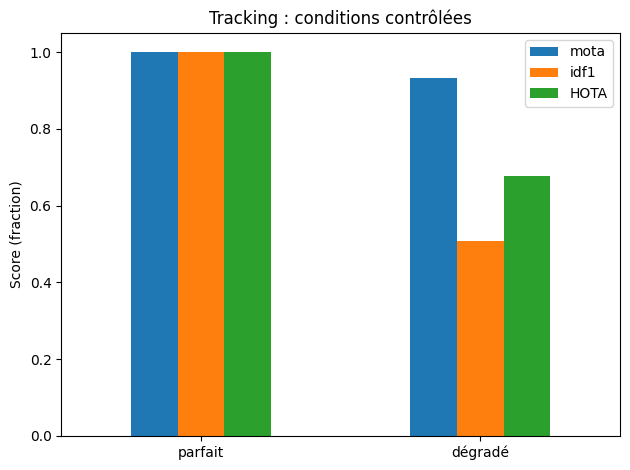

In [11]:
controlled_path=ROOT/'tracking'/'controlled_errors.mp4'
with imageio.get_writer(str(controlled_path),fps=12,codec='libx264',macro_block_size=2) as writer:
    for t in sorted(GT):
        im=Image.new('RGB',(480,270),'#EFF3F7'); draw=ImageDraw.Draw(im)
        draw.text((12,10),f'Frame {t+1} | GT vert / prediction orange',fill='black')
        for gid,(x,y,w,h) in GT[t]:
            cx=x+w/2
            draw.ellipse((cx-7,y+4,cx+7,y+18),fill='#637588')
            draw.line([(cx,y+20),(cx,y+45)],fill='#637588',width=5)
            draw.line([(cx,y+26),(x,y+38)],fill='#637588',width=4)
            draw.line([(cx,y+26),(x+w,y+38)],fill='#637588',width=4)
            draw.line([(cx,y+45),(x+3,y+h-3)],fill='#637588',width=4)
            draw.line([(cx,y+45),(x+w-3,y+h-3)],fill='#637588',width=4)
            draw.rectangle((x-2,y-2,x+w+2,y+h+2),outline='green',width=2)
        for pid,(x,y,w,h) in DEGRADED[t]:
            draw.rectangle((x,y,x+w,y+h),outline='#EB6B22',width=2)
            draw.text((x,y-12),f'ID {pid}',fill='#AA4000')
        writer.append_data(np.asarray(im))
display(Video(str(controlled_path),embed=True))
tracking_df[['mota','idf1','HOTA']].plot.bar(ylim=(0,1.05),rot=0,title='Tracking : conditions contrôlées')
plt.ylabel('Score (fraction)'); plt.tight_layout(); plt.show()
print('À retenir : des boîtes correctes peuvent masquer des identités fragmentées.')


# 2. Image Generation : générer un chat roux
**Prompt :** `a photograph of an orange cat sitting on a blue cushion, realistic, natural light`.

SD-Turbo synthétise des images. On mesure ensuite l'alignement avec le texte et le temps de génération. Un score automatique ne garantit ni des pattes correctes ni l'absence de duplications.

La génération peut produire une image moins convaincante que l'illustration de la présentation : cette dernière sert de support pédagogique et n'est **pas présentée comme une sortie mesurée de SD-Turbo**.


### Cellule 12 — Charger SD-Turbo

**Objectif.** Instancier le modèle de diffusion sur le CPU dans cette copie exécutée.

**Ce que fait le code.** Les poids sont chargés en bfloat16 sur CPU pour réduire la mémoire. Une seule étape et guidance_scale=0 correspondent au mode recommandé du modèle. Le chargement est séparé de la latence de génération.

**Résultat attendu.** Le pipeline est prêt sur le périphérique disponible ; dans cette copie exécutée, il s’agit du CPU.


In [12]:
pipe=None; generated_images=[]; generation_rows=[]
PROMPT='a photograph of an orange cat sitting on a blue cushion, realistic, natural light'
SEEDS=[11,22,33,44]
if RUN_GENERATION:
    from diffusers import AutoPipelineForText2Image
    start=time.perf_counter()
    pipe=AutoPipelineForText2Image.from_pretrained('stabilityai/sd-turbo',torch_dtype=torch.float16 if DEVICE=='cuda' else torch.bfloat16,variant='fp16')
    pipe=pipe.to(DEVICE)
    print('Chargement du modèle :',round(time.perf_counter()-start,2),'s')
else:
    print('Génération désactivée par configuration.')


Chargement du modèle : 9.06 s


/tmp/cv_execute_env/lib/python3.12/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


### Cellule 13 — Générer quatre variantes

**Objectif.** Faire varier la seed en gardant le reste du protocole constant.

**Ce que fait le code.** Chaque image est produite à 512 × 512 avec une étape. CUDA est synchronisé lorsqu’il est utilisé ; ici la mesure est réalisée sur CPU ; la première image peut rester plus lente à cause du démarrage.

**Résultat attendu.** Quatre fichiers PNG et un tableau des temps lorsque la génération est activée.


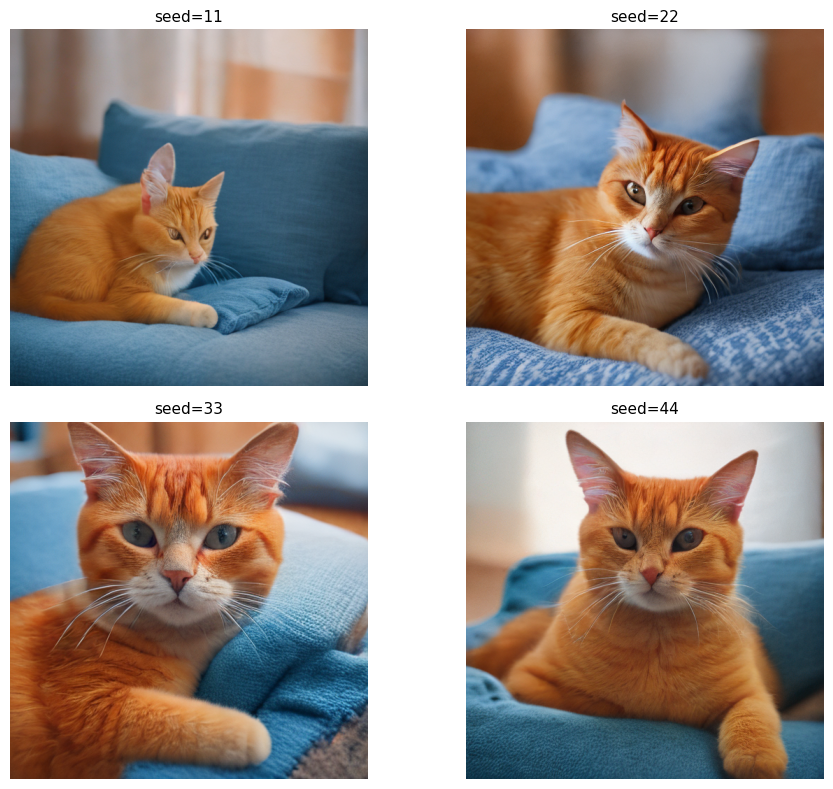

,seed,seconds
0,11,5.356044
1,22,5.322002
2,33,5.166533
3,44,5.211707


In [13]:
if pipe is not None:
    for seed in SEEDS:
        generator=torch.Generator(device=DEVICE).manual_seed(seed)
        if DEVICE=='cuda': torch.cuda.synchronize()
        start=time.perf_counter()
        image=pipe(prompt=PROMPT,num_inference_steps=1,guidance_scale=0.0,height=512,width=512,
                   generator=generator).images[0]
        if DEVICE=='cuda': torch.cuda.synchronize()
        seconds=time.perf_counter()-start
        image.save(ROOT/'generation'/f'cat_seed_{seed}.png')
        generated_images.append(image)
        generation_rows.append({'seed':seed,'seconds':seconds})
    show_gallery(generated_images,[f'seed={s}' for s in SEEDS],columns=2,size=(10,4))
    display(pd.DataFrame(generation_rows))
    del pipe; pipe=None; release_cuda()
else: print('Aucune image générée dans cette session ; poursuivre les autres parties est possible.')


### Cellule 14 — Définir un encodage CLIP commun

**Objectif.** Préparer une mesure texte-image réutilisable.

**Ce que fait le code.** CLIPModel renvoie les embeddings ; on normalise les vecteurs pour calculer un cosinus. On ne confond pas les logits CLIP avec une probabilité de vérité.

**Résultat attendu.** Une fonction de chargement et une fonction de similarité, utilisées pour CLIPScore puis pour le retrieval.


In [14]:
from transformers import CLIPModel,CLIPProcessor

def load_clip():
    model=CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(DEVICE).eval()
    processor=CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
    return model,processor

@torch.inference_mode()
def clip_cosines(model,processor,images,texts):
    inputs=processor(images=images,text=texts,return_tensors='pt',padding=True,truncation=True).to(DEVICE)
    result=model(**inputs)
    vi=torch.nn.functional.normalize(result.image_embeds,dim=-1)
    vt=torch.nn.functional.normalize(result.text_embeds,dim=-1)
    return (vi@vt.T).float().cpu().numpy()
print('Fonctions CLIP disponibles.')


Fonctions CLIP disponibles.


### Cellule 15 — Calculer CLIPScore et un texte témoin

**Objectif.** Mesurer l’alignement sémantique des images générées.

**Ce que fait le code.** Convention utilisée : 100 × max(cosinus, 0). Chaque image est comparée au prompt et à un texte sans chat. La différence est informative, pas une garantie de correction.

**Résultat attendu.** Un tableau de scores et un CSV. Si la génération a été ignorée, aucun faux score n’est produit.


In [15]:
if generated_images:
    clip_model,clip_processor=load_clip()
    texts=[PROMPT,'a red sports car parked in a city']
    cosines=clip_cosines(clip_model,clip_processor,generated_images,texts)
    for row,cosine in zip(generation_rows,cosines):
        row['CLIPScore']=float(100*max(cosine[0],0))
        row['CLIPScore_control']=float(100*max(cosine[1],0))
    generation_df=pd.DataFrame(generation_rows)
    generation_df.to_csv(ROOT/'generation'/'metrics.csv',index=False)
    report['generation']={'model':'stabilityai/sd-turbo','prompt':PROMPT,'steps':1,'guidance_scale':0.0,
                          'resolution':[512,512],'inference_device':DEVICE,'inference_dtype':'bfloat16' if DEVICE=='cpu' else 'float16','rows':generation_rows}
    display(generation_df)
    del clip_model,clip_processor; release_cuda()
else:
    report['generation']={'status':'not_executed','reason':'GPU indisponible ou option désactivée'}
    print('CLIPScore non calculé : aucune image SD-Turbo dans cette session.')


,seed,seconds,CLIPScore,CLIPScore_control
0,11,5.356044,37.293106,15.523005
1,22,5.322002,33.837479,15.798116
2,33,5.166533,34.265720,16.589552
3,44,5.211707,36.215359,16.647629


### Cellule 16 — Construire une grille d’audit humain

**Objectif.** Vérifier ce que CLIPScore peut manquer.

**Ce que fait le code.** Un tableau est créé sans remplir les jugements à votre place. Observer présence du chat, couleur, coussin, anatomie et diversité ; compléter ensuite le CSV dans un tableur.

**Résultat attendu.** Un fichier human_audit.csv. Ce fichier contient des champs à remplir, pas des mesures automatiques.


In [16]:
audit=pd.DataFrame([{'seed':seed,'chat_present':'','couleur_rousse':'','coussin_bleu':'',
                     'anatomie_coherente':'','duplication':'','commentaire':''} for seed in SEEDS[:len(generated_images)]])
audit.to_csv(ROOT/'generation'/'human_audit.csv',index=False)
display(audit)
print('Comparer les images entre elles : diversité ne signifie pas automatiquement qualité.')


Comparer les images entre elles : diversité ne signifie pas automatiquement qualité.


,seed,chat_present,couleur_rousse,coussin_bleu,anatomie_coherente,duplication,commentaire
0,11,,,,,,
1,22,,,,,,
2,33,,,,,,
3,44,,,,,,


### Cellule 17 — Extension : diversité perceptuelle LPIPS

**Objectif.** Comparer les images générées deux à deux.

**Ce que fait le code.** Cette cellule optionnelle télécharge un réseau perceptuel et convertit les images dans [-1,1]. Un LPIPS élevé indique des différences perceptuelles, pas forcément une meilleure génération.

**Résultat attendu.** Un tableau des six paires possibles pour quatre images, uniquement si RUN_LPIPS=True.


In [17]:
if RUN_LPIPS and len(generated_images)>=2:
    from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity
    metric=LearnedPerceptualImagePatchSimilarity(net_type='alex',normalize=False).to(DEVICE)
    tensors=[torch.from_numpy(np.array(im)).permute(2,0,1).float().unsqueeze(0).to(DEVICE)/127.5-1 for im in generated_images]
    rows=[]
    for i,j in itertools.combinations(range(len(tensors)),2):
        metric.reset()
        with torch.inference_mode(): value=float(metric(tensors[i],tensors[j]))
        rows.append({'seed_1':SEEDS[i],'seed_2':SEEDS[j],'LPIPS':value})
    pd.DataFrame(rows).to_csv(ROOT/'generation'/'lpips_pairs.csv',index=False)
    report['generation']['lpips_pairs']=rows
    display(pd.DataFrame(rows))
    del metric,tensors; release_cuda()
else: print('Extension LPIPS désactivée ou images insuffisantes.')


Extension LPIPS désactivée ou images insuffisantes.


## FID et KID : pourquoi on ne les calcule pas sur quatre chats
Ces métriques comparent des **distributions**. Le mini-catalogue de trois illustrations embarquées n'est pas un jeu de références réelles pour FID/KID.

La cellule suivante est volontairement optionnelle : importer un ZIP de **photos réelles de chats** et un ZIP d'images générées sous un protocole comparable. Elle exige au moins 100 images par lot comme **garde-fou pédagogique, sans garantie statistique**. Une vraie étude nécessite généralement beaucoup plus d'images, plusieurs répétitions et un protocole documenté.


### Cellule 18 — Extension : FID et KID sur deux lots importés

**Objectif.** Fournir le code de calcul sans produire un score trompeur sur quatre exemples.

**Ce que fait le code.** Les ZIP sont lus en mémoire sans extraction de chemins. Les images RGB sont redimensionnées à 299 × 299 avec le même traitement. Les lots sont tirés aléatoirement à taille égale.

**Résultat attendu.** FID et moyenne/écart-type de KID seulement si RUN_DISTRIBUTION=True et si des données suffisantes sont fournies. KID estimé peut être négatif.


In [18]:
if RUN_DISTRIBUTION:
    from google.colab import files
    import zipfile
    from torchmetrics.image.fid import FrechetInceptionDistance
    from torchmetrics.image.kid import KernelInceptionDistance
    def read_zip_images(label):
        print(label); uploaded=files.upload(); result=[]
        for data in uploaded.values():
            with zipfile.ZipFile(io.BytesIO(data)) as archive:
                for name in sorted(archive.namelist()):
                    if name.lower().endswith(('.jpg','.jpeg','.png')):
                        with Image.open(io.BytesIO(archive.read(name))) as image:
                            result.append(image.convert('RGB').resize((299,299),Image.Resampling.BILINEAR))
        return result
    real=read_zip_images('ZIP de photos réelles de chats, indépendant du générateur')
    fake=read_zip_images('ZIP d’images générées : même domaine et protocole connu')
    n=min(len(real),len(fake)); assert n>=100, 'Pas assez de données pour cette extension.'
    rng=np.random.default_rng(SEED)
    real=[real[i] for i in rng.permutation(len(real))[:n]]
    fake=[fake[i] for i in rng.permutation(len(fake))[:n]]
    fid=FrechetInceptionDistance(feature=2048,normalize=False).to(DEVICE)
    kid=KernelInceptionDistance(feature=2048,subsets=20,subset_size=min(100,n),normalize=False).to(DEVICE)
    torch.manual_seed(SEED)
    with torch.inference_mode():
        for lot,is_real in [(real,True),(fake,False)]:
            for start in range(0,n,16):
                batch=torch.stack([torch.from_numpy(np.asarray(im).copy()).permute(2,0,1) for im in lot[start:start+16]]).to(DEVICE)
                fid.update(batch,real=is_real); kid.update(batch,real=is_real)
        fid_value=float(fid.compute()); kid_mean,kid_std=kid.compute()
    distribution={'n_per_group':n,'FID':fid_value,'KID_mean':float(kid_mean),'KID_subset_std':float(kid_std),
                  'resize':'bilinear RGB 299x299, puis preprocessing interne identique'}
    report['generation']['distribution']=distribution
    print(distribution)
    print('L’écart-type des sous-lots KID n’est pas automatiquement un intervalle de confiance.')
    del fid,kid,real,fake; release_cuda()
else: print('FID/KID non calculés : extension désactivée ; aucun résultat de benchmark inventé.')


FID/KID non calculés : extension désactivée ; aucun résultat de benchmark inventé.


# 3. OCR, Captioning, Retrieval
Le troisième sujet de la présentation regroupe trois tâches liées aux images et au texte :
- **OCR** : retrouver exactement les caractères d'un document ;
- **captioning** : produire une phrase décrivant une scène ;
- **retrieval** : classer des images selon une requête.

## 3.1 OCR : lire « TOTAL 25 »
On utilise une image au texte connu, puis on compare version nette et version floue. Le CER inclut ici l'espace ; la normalisation est explicitement définie.


### Cellule 19 — Créer le document OCR de référence

**Objectif.** Connaître exactement le texte à reconnaître.

**Ce que fait le code.** PIL dessine TOTAL 25 avec une police système. Un filtre gaussien crée une deuxième version. Le document principal ne contient que le texte évalué pour ne pas mélanger détection de zones et transcription.

**Résultat attendu.** Deux images net/flou et une référence exacte, comme dans la présentation.


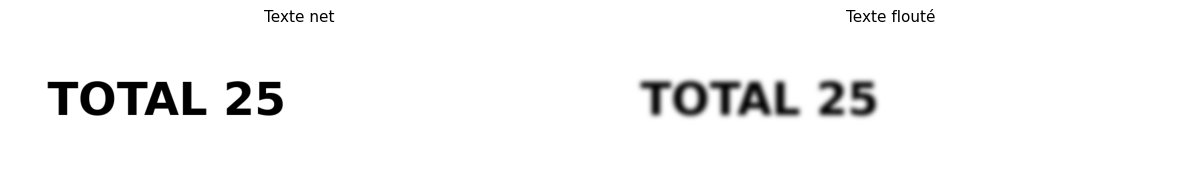

In [19]:
font_candidates=[Path('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf'),Path('/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf')]
font_path=next((p for p in font_candidates if p.exists()),None)
font=ImageFont.truetype(str(font_path),78) if font_path else ImageFont.load_default(size=78)
ocr_reference='TOTAL 25'
ocr_clean=Image.new('RGB',(1000,260),'white'); draw=ImageDraw.Draw(ocr_clean)
draw.text((65,75),ocr_reference,font=font,fill='black')
ocr_blurred=ocr_clean.filter(ImageFilter.GaussianBlur(radius=4))
ocr_clean.save(ROOT/'ocr'/'clean.png'); ocr_blurred.save(ROOT/'ocr'/'blurred.png')
show_gallery([ocr_clean,ocr_blurred],['Texte net','Texte flouté'],columns=2,size=(12,3))


### Cellule 20 — Reconnaître le texte avec EasyOCR

**Objectif.** Faire une véritable reconnaissance optique.

**Ce que fait le code.** EasyOCR charge ses poids de détection/reconnaissance et travaille sur CPU. Les boîtes sont triées de gauche à droite car notre exemple est monoligne. On transforme explicitement les sorties vides en chaîne vide.

**Résultat attendu.** Deux transcriptions réellement prédites. Un bon OCR peut réussir les deux versions ; le flou ne garantit pas une erreur.


In [20]:
import easyocr
reader=easyocr.Reader(['en'],gpu=False)
ocr_predictions={}
ocr_boxes={}
for label,image in [('net',ocr_clean),('flou',ocr_blurred)]:
    details=reader.readtext(np.asarray(image),detail=1,paragraph=False)
    details=sorted(details,key=lambda item:min(p[0] for p in item[0]))
    ocr_predictions[label]=' '.join(text for _,text,_ in details)
    ocr_boxes[label]=[{'text':text,'confidence':float(conf)} for _,text,conf in details]
    print(label,'→',repr(ocr_predictions[label]))
del reader; release_cuda()


net → 'TOTAL 25'
flou → 'TOTAL 25'


Using CPU. Note: This module is much faster with a GPU.
/tmp/cv_execute_env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


### Cellule 21 — Évaluer l’OCR avec CER et WER

**Objectif.** Mesurer les éditions nécessaires pour retrouver la référence.

**Ce que fait le code.** La normalisation met en majuscules et réduit les espaces multiples, sans supprimer les caractères difficiles. JiWER calcule CER/WER. Le contrôle TOTAL 2S reproduit le calcul de la slide, sans se faire passer pour une sortie du modèle.

**Résultat attendu.** Tableau des sorties EasyOCR, puis contrôle pédagogique : CER 12,5 % et WER 50 %.


In [21]:
import jiwer

def normalize_ocr(text):
    return re.sub(r'\s+',' ',text.upper()).strip()

ocr_rows=[]
for label,pred in ocr_predictions.items():
    norm=normalize_ocr(pred)
    ocr_rows.append({'condition':label,'reference':ocr_reference,'prediction':pred,'normalized':norm,
                     'CER':jiwer.cer(ocr_reference,norm),'WER':jiwer.wer(ocr_reference,norm)})
ocr_df=pd.DataFrame(ocr_rows)
ocr_df.to_csv(ROOT/'ocr'/'metrics.csv',index=False)
report['ocr']={'engine':'EasyOCR','normalization':'uppercase + collapse spaces; spaces included in CER',
               'rows':ocr_rows,'detections':ocr_boxes}
display(ocr_df)
control='TOTAL 2S'
assert np.isclose(jiwer.cer(ocr_reference,control),1/8)
assert np.isclose(jiwer.wer(ocr_reference,control),1/2)
print('Contrôle pédagogique distinct du modèle : CER =',jiwer.cer(ocr_reference,control),
      '| WER =',jiwer.wer(ocr_reference,control))
print(jiwer.visualize_alignment(jiwer.process_characters(ocr_reference,control)))


Contrôle pédagogique distinct du modèle : CER = 0.125 | WER = 0.5
=== SENTENCE 1 ===

REF: TOTAL 25
HYP: TOTAL 2S
            S

=== SUMMARY ===
number of sentences: 1
substitutions=1 deletions=0 insertions=0 hits=7

cer=12.50%



,condition,reference,prediction,normalized,CER,WER
0,net,TOTAL 25,TOTAL 25,TOTAL 25,0.0,0.0
1,flou,TOTAL 25,TOTAL 25,TOTAL 25,0.0,0.0


## 3.2 Captioning : décrire les images
**BLIP** génère une légende anglaise. Plusieurs références par image étaient définies avant les prédictions. Nous calculons BLEU-1, BLEU-4, METEOR et CIDEr.

Ces métriques mesurent des propriétés différentes. Une phrase peut partager des mots avec la référence tout en se trompant sur le nombre de personnes ou la couleur de la balle. Sur trois images, les résultats sont strictement pédagogiques ; le calcul de l'IDF de CIDEr est particulièrement peu stable.


### Cellule 22 — Charger BLIP et générer les légendes

**Objectif.** Implémenter le captioning avec un modèle préentraîné.

**Ce que fait le code.** BlipProcessor prépare les pixels ; generate produit des tokens ; decode transforme ces tokens en texte. eval et inference_mode désactivent l’entraînement.

**Résultat attendu.** Une légende prédite par image, enregistrée dans captions.json.


pedestrians → a couple walking across a crosswalk on a city street
cat → a cat sitting on top of a blue cushion
dog → a golden retrieve running with a ball in its mouth


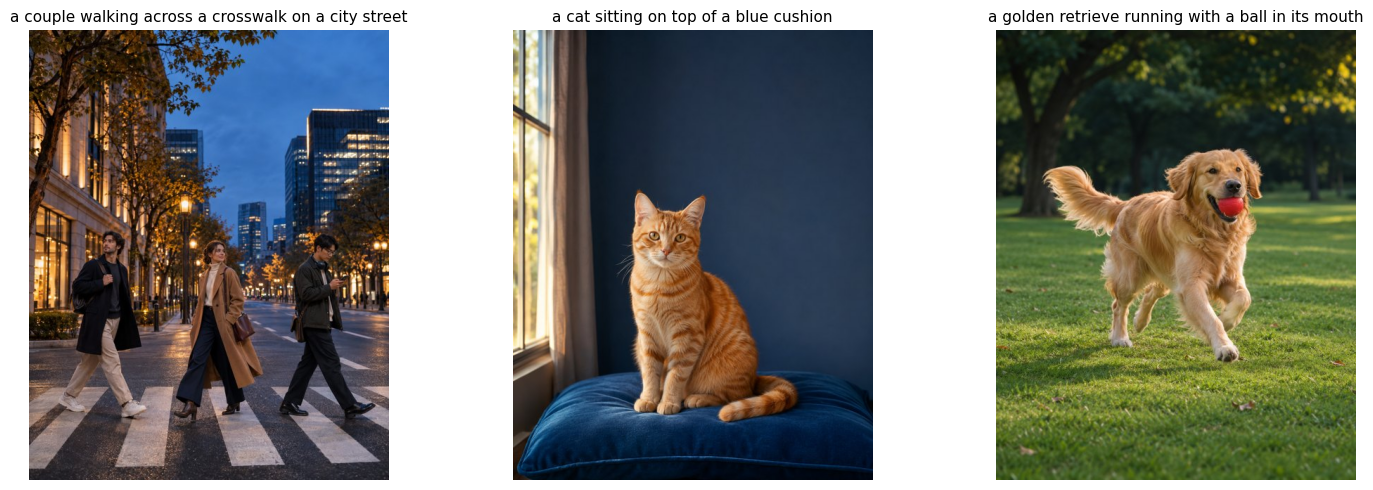

In [22]:
from transformers import BlipProcessor,BlipForConditionalGeneration
blip_processor=BlipProcessor.from_pretrained('Salesforce/blip-image-captioning-base')
blip_model=BlipForConditionalGeneration.from_pretrained('Salesforce/blip-image-captioning-base').to(DEVICE).eval()
captions={}
with torch.inference_mode():
    for name,image in catalogue.items():
        inputs=blip_processor(images=image,return_tensors='pt').to(DEVICE)
        output=blip_model.generate(**inputs,max_new_tokens=35,num_beams=3)
        captions[name]=blip_processor.decode(output[0],skip_special_tokens=True)
        print(name,'→',captions[name])
(ROOT/'captioning'/'captions.json').write_text(json.dumps(captions,ensure_ascii=False,indent=2))
del blip_model,blip_processor; release_cuda()
show_gallery(list(catalogue.values()),[captions[n] for n in catalogue],size=(15,5))


### Cellule 23 — Calculer BLEU et METEOR

**Objectif.** Comparer les légendes avec plusieurs formulations de référence.

**Ce que fait le code.** Une tokenisation simple et documentée retire la ponctuation. BLEU-4 est lissé car les phrases sont courtes ; ce choix est affiché. METEOR de NLTK utilise WordNet pour les synonymes. Les moyennes par image ne sont pas un BLEU de corpus.

**Résultat attendu.** Scores par image et moyennes. Ils ne sont pas directement comparables à un benchmark COCO officiel utilisant un autre tokenizer.


In [23]:
import nltk
from nltk.translate.bleu_score import sentence_bleu,SmoothingFunction
from nltk.translate.meteor_score import meteor_score
for resource in ['wordnet','omw-1.4']:
    try:
        try: nltk.data.find('corpora/'+resource)
        except LookupError: nltk.data.find('corpora/'+resource+'.zip')
    except LookupError:
        if not nltk.download(resource,quiet=True):
            raise RuntimeError('Dictionnaire NLTK indisponible : '+resource)

def tokenize_caption(text): return re.findall(r"[a-z0-9]+",text.lower())

caption_rows=[]
for name,pred in captions.items():
    refs=[tokenize_caption(r) for r in REFERENCES[name]]
    hyp=tokenize_caption(pred)
    row={'image':name,'prediction':pred,
         'BLEU1':float(sentence_bleu(refs,hyp,weights=(1,0,0,0))),
         'BLEU4_smoothed':float(sentence_bleu(refs,hyp,smoothing_function=SmoothingFunction().method1)),
         'METEOR':float(meteor_score(refs,hyp))}
    caption_rows.append(row)
caption_df=pd.DataFrame(caption_rows)
display(caption_df)
print('Moyennes des scores par image :'); display(caption_df.select_dtypes('number').mean())


Moyennes des scores par image :


/tmp/cv_execute_env/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(


,image,prediction,BLEU1,BLEU4_smoothed,METEOR
0,pedestrians,a couple walking across a crosswalk on a city ...,0.500000,0.167845,0.573864
1,cat,a cat sitting on top of a blue cushion,0.777778,0.146685,0.727023
2,dog,a golden retrieve running with a ball in its m...,0.800000,0.354948,0.778906


BLEU1             0.692593
BLEU4_smoothed    0.223159
METEOR            0.693264
dtype: float64

### Cellule 24 — Calculer CIDEr sur le mini-corpus

**Objectif.** Montrer le calcul de consensus TF-IDF.

**Ce que fait le code.** Le scorer Python CIDEr de pycocoevalcap reçoit les mêmes tokens normalisés sous forme de chaînes. La partie Java/SPICE n’est pas utilisée. On conserve les scores par image et le score global.

**Résultat attendu.** Un CIDEr pédagogique sur trois images. Une valeur faible peut venir du vocabulaire ou de la petite taille du corpus, pas seulement de la qualité du modèle.


In [24]:
from pycocoevalcap.cider.cider import Cider
names=list(catalogue)
gts={i:[' '.join(tokenize_caption(r)) for r in REFERENCES[name]] for i,name in enumerate(names)}
res={i:[' '.join(tokenize_caption(captions[name]))] for i,name in enumerate(names)}
cider_global,cider_per_image=Cider().compute_score(gts,res)
caption_df['CIDEr']=np.asarray(cider_per_image,dtype=float)
caption_df.to_csv(ROOT/'captioning'/'metrics.csv',index=False)
report['captioning']={'model':'Salesforce/blip-image-captioning-base',
    'tokenization':'lowercase, regex [a-z0-9]+ ; not official COCO PTBTokenizer',
    'BLEU4_smoothing':'NLTK method1','CIDEr_global':float(cider_global),
    'rows':caption_df.to_dict(orient='records')}
display(caption_df)
print('CIDEr global :',float(cider_global),'| mini-corpus, pas un benchmark COCO')


CIDEr global : 1.8827823796185212 | mini-corpus, pas un benchmark COCO


,image,prediction,BLEU1,BLEU4_smoothed,METEOR,CIDEr
0,pedestrians,a couple walking across a crosswalk on a city ...,0.500000,0.167845,0.573864,1.623683
1,cat,a cat sitting on top of a blue cushion,0.777778,0.146685,0.727023,1.604559
2,dog,a golden retrieve running with a ball in its m...,0.800000,0.354948,0.778906,2.420106


### Cellule 25 — Préparer une vérification factuelle des légendes

**Objectif.** Compléter les métriques lexicales par l’observation.

**Ce que fait le code.** On affiche les références et les prédictions côte à côte. Un CSV comporte des champs à remplir pour objet, couleur, nombre et action.

**Résultat attendu.** Un tableau de comparaison et une grille d’audit vierge.


In [25]:
comparison=pd.DataFrame([{'image':n,'references':' | '.join(REFERENCES[n]),'prediction':captions[n]} for n in catalogue])
display(comparison)
review=comparison.copy()
for col in ['objet_correct','couleur_correcte','nombre_correct','action_correcte','commentaire']:
    review[col]=''
review.to_csv(ROOT/'captioning'/'human_review.csv',index=False)
print('Exemple à vérifier : le chien porte-t-il une balle rouge dans la légende ?')


Exemple à vérifier : le chien porte-t-il une balle rouge dans la légende ?


,image,references,prediction
0,pedestrians,three people are crossing a city street | pede...,a couple walking across a crosswalk on a city ...
1,cat,an orange cat sits on a blue cushion | a ginge...,a cat sitting on top of a blue cushion
2,dog,a dog runs in a green park with a red ball | a...,a golden retrieve running with a ball in its m...


## 3.3 Retrieval : retrouver une image avec une requête
On réutilise CLIP pour encoder le mini-catalogue et les requêtes `a cat`, `a dog`, `pedestrians`. Les pertinences étaient fixées avant le classement.

- **R@K (convention hit rate)** : proportion de requêtes pour lesquelles au moins une image pertinente apparaît parmi les K premières.
- **MRR** : moyenne de l'inverse du rang du premier résultat pertinent.
- Avec plusieurs images pertinentes, ce R@K n'est pas le rappel documentaire fractionnaire.
- Un catalogue de trois images rend la tâche très facile : le résultat explique la méthode sans mesurer une performance générale.


### Cellule 26 — Encoder et classer les images avec CLIP

**Objectif.** Implémenter la recherche texte → images.

**Ce que fait le code.** La fonction commune fournit une matrice images × textes. On la transpose pour obtenir une ligne par requête puis on classe les similarités décroissantes. Les logits ne sont pas convertis en probabilités.

**Résultat attendu.** La matrice de cosinus et le classement des trois images pour chaque requête.


In [26]:
clip_model,clip_processor=load_clip()
image_names=list(catalogue)
similarity=clip_cosines(clip_model,clip_processor,list(catalogue.values()),QUERIES).T
order=np.argsort(-similarity,axis=1,kind='stable')
sim_df=pd.DataFrame(similarity,index=QUERIES,columns=image_names)
sim_df.to_csv(ROOT/'retrieval'/'cosine_similarity.csv')
display(sim_df)
for query,ranks in zip(QUERIES,order):
    print(query,'→',[image_names[i] for i in ranks])
del clip_model,clip_processor; release_cuda()


a cat → ['cat', 'dog', 'pedestrians']
a dog → ['dog', 'cat', 'pedestrians']
pedestrians → ['pedestrians', 'dog', 'cat']


,pedestrians,cat,dog
a cat,0.141699,0.271375,0.199182
a dog,0.147366,0.221539,0.263949
pedestrians,0.257169,0.200542,0.213619


### Cellule 27 — Calculer R@K et MRR

**Objectif.** Évaluer les classements selon les jugements de pertinence.

**Ce que fait le code.** Le premier rang pertinent vaut 1 pour une première position. Une requête sans pertinent dans le catalogue reçoit un rang infini et un réciproque nul. Les K ne dépassent pas la taille du catalogue.

**Résultat attendu.** R@1, R@2, R@3 et MRR sur les vraies prédictions de CLIP, plus un contrôle mathématique indépendant.


In [27]:
def retrieval_metrics(rankings,relevant,image_names,ks=(1,2,3)):
    first_ranks=[]
    for ordered,rel in zip(rankings,relevant):
        rank=next((position for position,i in enumerate(ordered,1) if image_names[i] in rel),float('inf'))
        first_ranks.append(rank)
    ranks=np.asarray(first_ranks,dtype=float)
    metrics={f'R@{k}':float(np.mean(ranks<=k)) for k in ks if k<=len(image_names)}
    metrics['MRR']=float(np.mean(np.divide(1.0,ranks,out=np.zeros_like(ranks),where=np.isfinite(ranks))))
    return metrics,first_ranks

retrieval_scores,first_ranks=retrieval_metrics(order,RELEVANT,image_names)
retrieval_df=pd.DataFrame({'query':QUERIES,'first_relevant_rank':first_ranks,
    'top1':[image_names[o[0]] for o in order],'relevant':[' | '.join(sorted(s)) for s in RELEVANT]})
retrieval_df.to_csv(ROOT/'retrieval'/'ranks.csv',index=False)
report['retrieval']={'model':'openai/clip-vit-base-patch32','scores':retrieval_scores,
    'convention':'R@K = at least one relevant item in top K', 'queries':QUERIES,
    'relevant':[sorted(s) for s in RELEVANT], 'ranks':first_ranks}
print('Scores CLIP mesurés :',retrieval_scores); display(retrieval_df)
# Contrôle pédagogique de la présentation, distinct du catalogue actuel.
control_ranks=np.array([1,3,5],dtype=float)
assert np.isclose(np.mean(control_ranks<=1),1/3)
assert np.isclose(np.mean(control_ranks<=3),2/3)
assert np.isclose(np.mean(1/control_ranks),23/45)
print('Contrôle rangs [1,3,5] : R@1=33,3 %, R@3=66,7 %, MRR≈51,1 %.')


Scores CLIP mesurés : {'R@1': 1.0, 'R@2': 1.0, 'R@3': 1.0, 'MRR': 1.0}
Contrôle rangs [1,3,5] : R@1=33,3 %, R@3=66,7 %, MRR≈51,1 %.


,query,first_relevant_rank,top1,relevant
0,a cat,1,cat,cat
1,a dog,1,dog,dog
2,pedestrians,1,pedestrians,pedestrians


### Cellule 28 — Afficher les résultats de recherche

**Objectif.** Voir les erreurs éventuelles de classement.

**Ce que fait le code.** Les trois images sont présentées dans l’ordre de CLIP, avec une indication pertinent/non pertinent issue des annotations indépendantes.

**Résultat attendu.** Une galerie par requête ; le score s’explique visuellement.


Requête : a cat
Requête : a dog
Requête : pedestrians


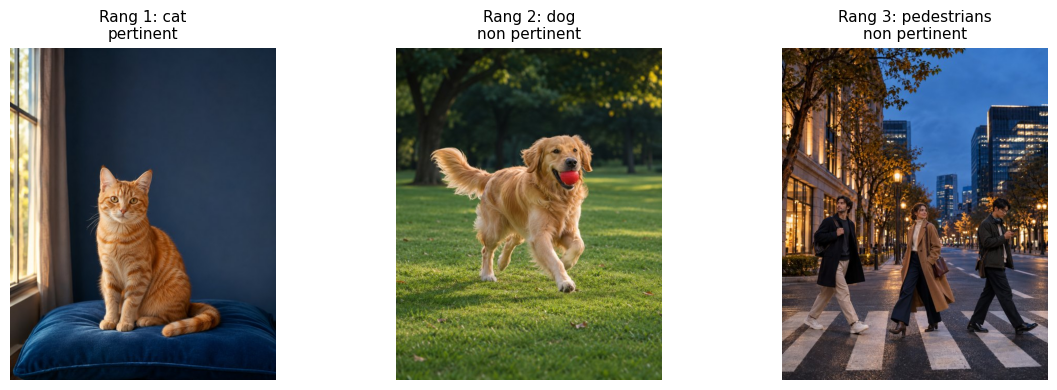

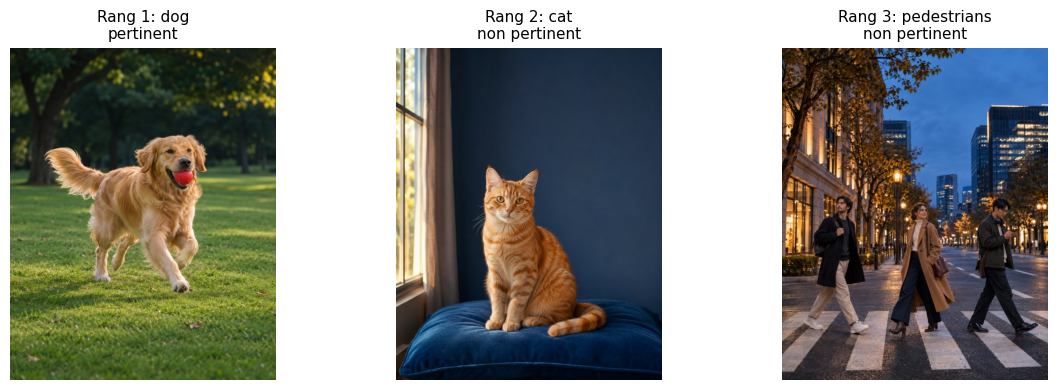

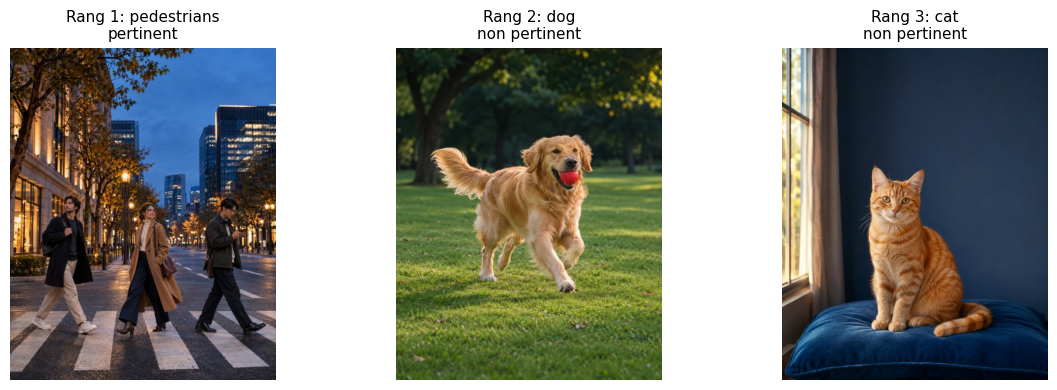

In [28]:
for query,indices,rel in zip(QUERIES,order,RELEVANT):
    print('Requête :',query)
    show_gallery([catalogue[image_names[i]] for i in indices],
                 [f'Rang {rank}: {image_names[i]}\n'+('pertinent' if image_names[i] in rel else 'non pertinent')
                  for rank,i in enumerate(indices,1)],columns=3,size=(12,4))


# 4. Bilan, traçabilité et export
Les trois sujets sont réunis, mais leurs scores ne sont **pas directement comparables** : 0,9 en MOTA n'a pas le même sens qu'un CLIPScore de 90.

| Sujet | Ce qui est mesuré | Limite principale |
|---|---|---|
| Tracking réel | IDs, boîtes, temps du pipeline | Pas de score de qualité sans GT annotée |
| Tracking contrôlé | MOTA, IDF1, HOTA | Séquence synthétique très simple |
| Génération | CLIPScore, latence, audit ; extensions LPIPS/FID/KID | Peu d'images ; pas de classement scientifique |
| OCR | CER et WER | Document monoligne artificiel |
| Captioning | BLEU-1/4, METEOR, CIDEr | Trois illustrations, tokenizer pédagogique |
| Retrieval | R@K, MRR | Trois images, catégories faciles |

Pour un vrai projet : agrandir les jeux de test, séparer les données de réglage et de test, fixer les protocoles, puis comparer plusieurs systèmes dans les mêmes conditions.


### Cellule 29 — Sauvegarder les résultats et versions

**Objectif.** Rendre l’expérience vérifiable et partageable.

**Ce que fait le code.** Les métriques sont stockées dans un JSON. Les versions exactes installées sont enregistrées, avec les paramètres et les origines des données. Les scores non exécutés restent explicitement absents.

**Résultat attendu.** results.json, environment.json et un tableau récapitulatif.


In [29]:
packages=['torch','torchvision','ultralytics','diffusers','transformers','accelerate','numpy','pandas',
          'motmetrics','easyocr','jiwer','nltk','pycocoevalcap','torchmetrics','torch-fidelity']
versions={}
for package in packages:
    try: versions[package]=metadata.version(package)
    except metadata.PackageNotFoundError: versions[package]='not installed'
report['environment']={'python':sys.version,'packages':versions,'device':DEVICE,'generation_cpu_bfloat16':True,
    'video_source':VIDEO_SOURCE,'max_frames':MAX_FRAMES,
    'illustrations':'AI-generated embedded JPEGs; pedagogical mini-corpus',
    'validation_note':'Model metrics computed only after executing this notebook.'}

def json_default(value):
    if isinstance(value,np.generic): return value.item()
    if isinstance(value,np.ndarray): return value.tolist()
    if isinstance(value,Path): return str(value)
    raise TypeError(type(value).__name__)

(ROOT/'results.json').write_text(json.dumps(report,ensure_ascii=False,indent=2,default=json_default))
(ROOT/'environment.json').write_text(json.dumps(report['environment'],ensure_ascii=False,indent=2))
summary=[{'task':'Tracking contrôlé','metric':k,'value':v} for k,v in tracking_metrics['dégradé'].items()]
summary += [{'task':'Retrieval','metric':k,'value':v} for k,v in retrieval_scores.items()]
summary += [{'task':'OCR moyen','metric':k,'value':float(ocr_df[k].mean())} for k in ['CER','WER']]
summary += [{'task':'Captioning moyen','metric':k,'value':float(caption_df[k].mean())}
            for k in ['BLEU1','BLEU4_smoothed','METEOR','CIDEr']]
if generation_rows and 'CLIPScore' in generation_rows[0]:
    summary.append({'task':'Génération','metric':'CLIPScore moyen','value':float(np.mean([r['CLIPScore'] for r in generation_rows]))})
summary_df=pd.DataFrame(summary);summary_df.to_csv(ROOT/'summary.csv',index=False)
display(summary_df)
print('Résultats enregistrés dans',ROOT.resolve())


Résultats enregistrés dans /workspace/scratch/aaef0a09509f/executed_cv_work/cv_results


,task,metric,value
0,Tracking contrôlé,mota,0.933333
1,Tracking contrôlé,idf1,0.508475
2,Tracking contrôlé,num_switches,2.000000
3,Tracking contrôlé,num_false_positives,1.000000
4,Tracking contrôlé,num_misses,5.000000
5,Tracking contrôlé,HOTA,0.676749
6,Retrieval,R@1,1.000000
7,Retrieval,R@2,1.000000
8,Retrieval,R@3,1.000000
9,Retrieval,MRR,1.000000


### Cellule 30 — Créer et télécharger le ZIP des sorties

**Objectif.** Conserver les résultats avant la fermeture de Colab.

**Ce que fait le code.** shutil.make_archive archive le dossier cv_results. Dans Colab, files.download lance le téléchargement. Un README de sortie rappelle les limites des scores.

**Résultat attendu.** cv_results_export.zip contenant les images, vidéos, trajectoires, métriques et annotations.


In [30]:
(ROOT/'README_RESULTS.txt').write_text(
    'Résultats du notebook de vision par ordinateur — El Mehdi FATAHLLAH.\n'
    'Tracking réel : pas de score de qualité sans annotations.\n'
    'Tracking contrôlé : GT synthétique, résultats séparés de YOLO.\n'
    'Images embarquées : illustrations IA, mini-corpus pédagogique.\n'
    'Génération SD-Turbo : scores présents uniquement si le modèle a été exécuté.\n'
    'FID/KID : optionnels et nécessitent deux vrais lots indépendants et documentés.\n'
    'Conserver environment.json pour les versions exactes.\n',encoding='utf-8')
archive=shutil.make_archive('cv_results_export','zip',root_dir=str(ROOT.parent),base_dir=ROOT.name)
print('Archive créée :',Path(archive).resolve())
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Hors Colab : télécharger le ZIP depuis le dossier courant.')


Archive créée : /workspace/scratch/aaef0a09509f/executed_cv_work/cv_results_export.zip
Hors Colab : télécharger le ZIP depuis le dossier courant.


## Résumé à retenir pour l'oral
1. **Tracking** : une bonne détection ne garantit pas la stabilité de l'identité. Comparer MOTA, IDF1 et HOTA.
2. **Génération** : distinguer fidélité au texte, réalisme et diversité. Ne pas annoncer un FID sérieux sur quatre images.
3. **OCR / captioning / retrieval** : transcription exacte, description sémantique et pertinence du classement ont des métriques différentes.
4. Les exemples du notebook sont pédagogiques ; leurs résultats ne constituent pas un benchmark général.

## Dépannage
- **GPU absent** : cette copie permet aussi une exécution CPU ; les temps peuvent être plus longs.
- **CUDA out of memory** : redémarrer la session, exécuter dans l'ordre ; ne pas conserver d'autres modèles dans la même session.
- **Téléchargement de vidéo impossible** : mettre `VIDEO_SOURCE='upload'` dans la configuration et importer un court MP4 de piétons.
- **Téléchargement de poids interrompu / 429** : patienter, puis relancer la cellule de chargement ; les images embarquées ne dépendent d'aucun lien externe.
- **WordNet absent** : relancer la cellule BLEU/METEOR lorsque l'accès réseau est rétabli ; ne pas remplacer silencieusement la métrique par une autre.
- **OCR identique sur net et flou** : c'est un résultat possible ; augmenter le rayon du flou et documenter le changement.
- **Images BLIP/CLIP différentes des références** : relire les annotations avant de conclure ; vérifier notamment nombre, couleur et action.

## Sources primaires et documentation
- Ultralytics, tracking : https://docs.ultralytics.com/modes/track/
- Vidéo de démonstration publiée dans le tutoriel : https://academy.ultralytics.com/courses/yolo-in-production/tracking-with-bytetrack-and-botsort
- motmetrics : https://github.com/cheind/py-motmetrics
- HOTA, Luiten et al. : https://arxiv.org/abs/2009.07736 ; référence d'implémentation : https://github.com/JonathonLuiten/TrackEval
- SD-Turbo : https://huggingface.co/stabilityai/sd-turbo
- CLIPScore : https://arxiv.org/abs/2104.08718 ; convention de score utilisée explicitée dans la cellule.
- FID : https://arxiv.org/abs/1706.08500 ; KID : https://arxiv.org/abs/1801.01401
- TorchMetrics FID : https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance.html
- EasyOCR : https://github.com/JaidedAI/EasyOCR
- JiWER : https://jitsi.github.io/jiwer/usage/
- BLIP : https://huggingface.co/Salesforce/blip-image-captioning-base
- BLEU : https://aclanthology.org/P02-1040/ ; METEOR NLTK : https://www.nltk.org/api/nltk.translate.meteor_score.html
- CIDEr : https://openaccess.thecvf.com/content_cvpr_2015/html/Vedantam_CIDEr_Consensus-Based_Image_2015_CVPR_paper.html ; scorer Python : https://github.com/salaniz/pycocoevalcap
- CLIP : https://huggingface.co/openai/clip-vit-base-patch32

**Validation du fichier livré :** la structure du notebook, la syntaxe et les blocs CPU de calcul des métriques sont vérifiés lors de sa préparation. Les sorties de cette copie proviennent de l’exécution réelle sur CPU ; consulter le bilan en tête du document.
